# PRIME: Protonation-number Reweighting for pH-Dependent Free Energy Calculations
## A demonstration notebook
Stefan Hervø-Hansen<sup>a</sup> and Nobuyuki Matubayasi<sup>a</sup><br><br>
<sup>a</sup>Division of Chemical Engineering, Graduate School of Engineering Science, The University of Osaka, Toyonaka, Osaka 560-8531, Japan.<br>
*Correspondence:* stefan@cheng.es.osaka-u.ac.jp, nobuyuki@cheng.es.osaka-u.ac.jp

---

This notebook is educational. It accompanies the manuscript and the `prime` package and shows, on models whose answers are known, how PRIME turns the protonation records of a set of pH windows into the pH-independent weights of the protonation numbers and the free energy, when it can do so, and what the consistency test of the windows looks for. The paper notebook (`PRIME_paper.ipynb`) reproduces the figures of the manuscript from the insulin records. This one explains them. The estimator is always the `prime` package, every section runs on its own after the imports, and all figures and animations are written to `Animations/`. A full run takes about 20 minutes, most of it rendering.

| Section | Question | Output |
|---|---|---|
| 1. Three windows and the PRIME equations | What does PRIME do with the records of the windows? | `PRIME_Ilustrative_Figure.png` |
| 2. The fixed-point iteration | How does it find the potentials? | `PRIME_full_reconstruction_movie` |
| 3. The limit of the method | When do the windows carry too little information? | `PRIME_symmetrical_moving_ph` |
| 4. Window bias from a slow degree of freedom | What if the windows do not sample the same conformational space? | `PRIME_slow_conformation`, `PRIME_slow_conformation_soft`, `PRIME_bias_vs_sampling` |
| 5. The consequence for the free energy | What does such a bias do to the free energy? | `PRIME_consistency_mechanism`, `PRIME_consistency_control`, `PRIME_consistency_slow_vs_fast` |

The thread. Sections 1 to 3 take every window to be a faithful sample of the molecule at its pH and ask what PRIME makes of such windows, how it solves its equations, and where the information runs out. Sections 4 and 5 drop that assumption, because in a simulation it is the one most easily broken, and ask how the break can be seen in the records themselves and what it costs in the free energy.

In [1]:
import os
import warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from scipy.interpolate import make_interp_spline
import prime

os.makedirs("Animations", exist_ok=True)
LN10 = np.log(10.0)


def assignment(g, H, pHs):
    '''Pr(k | N), the share of every window in the pooled records of N for the potentials g (Eq. 18).'''
    lw = np.log(H.sum(axis=1))[:, None] + g[:, None] - LN10 * np.outer(pHs, np.arange(H.shape[1]))
    return np.exp(lw - np.logaddexp.reduce(lw, axis=0))


def iterate(H, pHs, g, n=1, mix=0.25):
    '''n fixed-point iterations of the PRIME equations from g.'''
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", prime.PRIMEWarning)
        return prime.solve_prime(H, pHs, method="fixedpoint", mix=mix, g_init=g, max_iter=n, tol=0.0)


def iteration_history(H, pHs, mix=0.25, tol=1e-6, max_iter=500):
    '''Potentials after every fixed-point iteration from equal potentials, and the size of each step.'''
    history, steps = [np.zeros(len(pHs))], []
    for _ in range(max_iter):
        g = iterate(H, pHs, history[-1], mix=mix)
        steps.append(np.max(np.abs(g - history[-1])))
        history.append(g)
        if steps[-1] < tol:
            break
    return history, steps


# 1. Three windows and the PRIME equations

A constant-pH simulation at pH$_k$ samples the semi-grand ensemble, in which a configuration with $N$ protons on the molecule carries the extra weight $10^{-N\,\mathrm{pH}_k}$. The pH enters the weight of a configuration only through its protonation number $N$. Summing the Boltzmann weights of all configurations with the same $N$ gives the pH-independent weights of the protonation numbers, $c(N)$, and the distribution of $N$ in a window is

$$\Pr(N \mid k) = \frac{c(N)\,10^{-N\,\mathrm{pH}_k}}{\sum_{N'} c(N')\,10^{-N'\,\mathrm{pH}_k}} .$$

Every window therefore looks at the same $c(N)$ through a different exponential filter, and a window has records only at the $N$ that its filter leaves visible. PRIME is the maximum-likelihood estimate of $c(N)$ from the histograms $H_k(N)$ of $K$ windows with $M_k$ records each, which is MBAR written for the semi-grand ensemble. With the aggregated histogram of all windows, $H_\mathrm{tot}(N) = \sum_k H_k(N)$, the estimate is (Eq. 22 of the manuscript)

$$c(N) = \frac{H_\mathrm{tot}(N)}{\sum_k M_k \exp\!\left[\beta\Delta\Upsilon_k - N\,\mathrm{pH}_k \ln 10\right]}, \qquad e^{-\beta\Delta\Upsilon_k} = \sum_N c(N)\,10^{-N\,\mathrm{pH}_k},$$

where $\beta\Delta\Upsilon_k$ is the free energy of window $k$ on the scale set by $c(N)$. The two equations determine each other. Once $c(N)$ is known, the free energy at any pH follows from the same sum (Eq. 23),

$$\beta\Delta\Upsilon(\mathrm{pH}) = -\ln \sum_N c(N)\,10^{-N\,\mathrm{pH}},$$

and so does the mean protonation number $\langle N \rangle$ at that pH (Eq. 24), which is the derivative of $\beta\Delta\Upsilon$ with respect to pH divided by $\ln 10$.

A useful way to read the equations is as an assignment of records to windows. For given potentials, the share of window $k$ in the records of protonation number $N$ from all windows is (Eq. 18)

$$\Pr(k \mid N) = \frac{M_k \exp\!\left[\beta\Delta\Upsilon_k - N\,\mathrm{pH}_k \ln 10\right]}{\sum_{k'} M_{k'} \exp\!\left[\beta\Delta\Upsilon_{k'} - N\,\mathrm{pH}_{k'} \ln 10\right]} ,$$

and the PRIME equations hold exactly when every window gets back its own number of records, $\sum_N H_\mathrm{tot}(N)\,\Pr(k \mid N) = M_k$. The potentials are the dials that move the shares. The solution is the setting at which the aggregated histogram, split by the shares, reproduces every window.

The figure shows this on three windows of a molecule with nine protonation states. The weights $c(N)$ are a Gaussian in $N$, so every window is a Gaussian of the same width whose center moves with the pH, and each window holds 1000 records. Left, the aggregated histogram that PRIME works from. Middle, the shares $\Pr(k \mid N)$ at the solution of `prime.solve_prime`, with the potentials written on the curves (the panels write $m$ for the window index). Right, the aggregated histogram split by the shares (squares) on top of the windows themselves (open circles). At the solution the two coincide for every window.

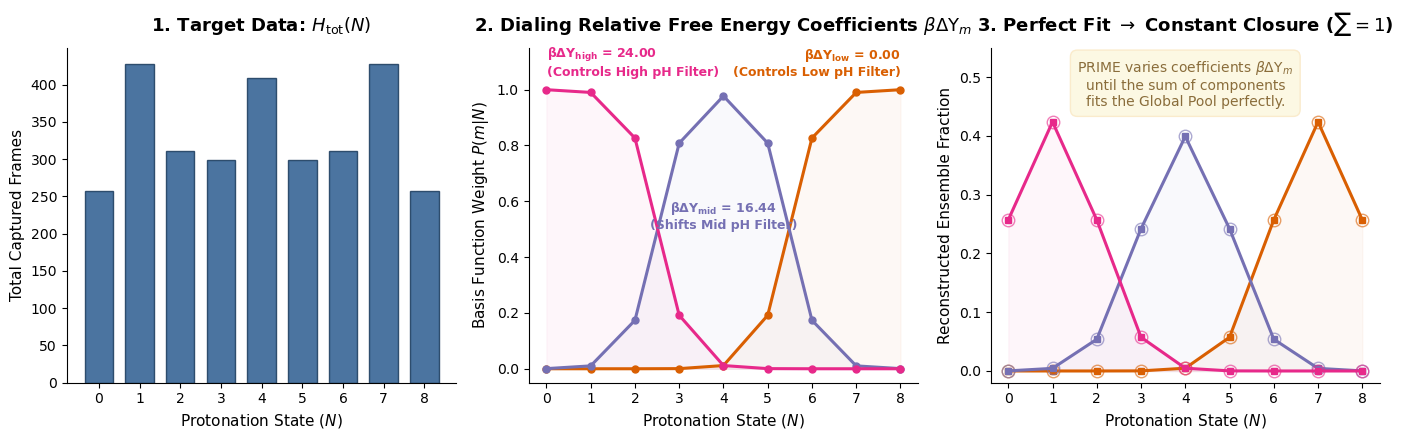

In [2]:
# Three windows on a molecule with nine protonation states. The weights are a Gaussian in N, so every
# window is a Gaussian of the same width whose center moves with the pH (centers at N = 7, 4 and 1).
N_vals = np.arange(9)
sigma = 1.0
lnc_demo = -(N_vals - 7.0) ** 2 / (2 * sigma ** 2) + 5.0 * LN10 * N_vals
pH_demo = 5.0 + np.array([0.0, 3.0, 6.0]) / (sigma ** 2 * LN10)
H_demo = np.array([1000 * prime.distribution(lnc_demo, pH)[1] for pH in pH_demo])
H_tot = H_demo.sum(axis=0)
g_demo = prime.solve_prime(H_demo, pH_demo)
P_demo = assignment(g_demo, H_demo, pH_demo)
colors_m = ['#d95f02', '#7570b3', '#e7298a']
names_m = ['low', 'mid', 'high']


def plot_prime_with_explicit_free_energy():
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4.5))

    # Panel 1: the pooled histogram
    ax1.bar(N_vals, H_tot, color='#2b5c8f', edgecolor='#1a3a5c', width=0.7, alpha=0.85)
    ax1.set_title(r"1. Target Data: $H_{\mathrm{tot}}(N)$", fontsize=13, weight='bold', pad=12)
    ax1.set_xlabel('Protonation State ($N$)', fontsize=11)
    ax1.set_ylabel('Total Captured Frames', fontsize=11)
    ax1.set_xticks(N_vals)

    # Panel 2: the assignment, with the fitted potentials written on the curves
    for P, color in zip(P_demo, colors_m):
        ax2.plot(N_vals, P, '-o', color=color, linewidth=2.2, markersize=5)
        ax2.fill_between(N_vals, 0, P, color=color, alpha=0.04)
    ax2.text(0.01, 1.05, r"$\mathbf{\beta\Delta\Upsilon_{high}}$ = " + f"{g_demo[2]:.2f}" + "\n(Controls High pH Filter)",
             color=colors_m[2], fontsize=9, ha='left', weight='bold')
    ax2.text(4.0, 0.5, r"$\mathbf{\beta\Delta\Upsilon_{mid}}$ = " + f"{g_demo[1]:.2f}" + "\n(Shifts Mid pH Filter)",
             color=colors_m[1], fontsize=9, ha='center', weight='bold')
    ax2.text(8.0, 1.05, r"$\mathbf{\beta\Delta\Upsilon_{low}}$ = " + f"{g_demo[0]:.2f}" + "\n(Controls Low pH Filter)",
             color=colors_m[0], fontsize=9, ha='right', weight='bold')
    ax2.set_title(r"2. Dialing Relative Free Energy Coefficients $\beta\Delta\Upsilon_m$", fontsize=13, weight='bold', pad=12)
    ax2.set_xlabel('Protonation State ($N$)', fontsize=11)
    ax2.set_ylabel('Basis Function Weight $P(m|N)$', fontsize=11)
    ax2.set_ylim(-0.05, 1.15)
    ax2.set_xticks(N_vals)

    # Panel 3: the pooled histogram split by the assignment gives every window back
    for P, H, color in zip(P_demo, H_demo, colors_m):
        ax3.plot(N_vals, H_tot * P / 1000, '-s', color=color, linewidth=2.2, markersize=5)
        ax3.plot(N_vals, H / 1000, 'o', color=color, markersize=9, markerfacecolor='none', alpha=0.6)
        ax3.fill_between(N_vals, 0, H_tot * P / 1000, color=color, alpha=0.04)
    ax3.set_title(r"3. Perfect Fit $\rightarrow$ Constant Closure ($\sum=1$)", fontsize=13, weight='bold', pad=12)
    ax3.set_xlabel('Protonation State ($N$)', fontsize=11)
    ax3.set_ylabel('Reconstructed Ensemble Fraction', fontsize=11)
    ax3.set_ylim(-0.02, 0.55)
    ax3.set_xticks(N_vals)
    ax3.text(4.0, 0.45, r"PRIME varies coefficients $\beta\Delta\Upsilon_m$" + "\n" + r"until the sum of components" + "\n" + r"fits the Global Pool perfectly.",
             bbox=dict(facecolor='#fcf8e3', edgecolor='#faebcc', boxstyle='round,pad=0.5'),
             fontsize=10, ha='center', color='#8a6d3b')

    for ax in [ax1, ax2, ax3]:
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.tick_params(axis='both', labelsize=10)

    plt.tight_layout()
    plt.savefig("Animations/PRIME_Ilustrative_Figure.png", dpi=300, bbox_inches='tight')
    return fig


fig = plot_prime_with_explicit_free_energy()
plt.show()


# 2. Animation: the fixed-point iteration

The two equations of Section 1 are solved by iterating them. From a guess of the potentials the first equation gives $c(N)$, the second gives new potentials, and the step is damped by a mixing factor. `prime.solve_prime` does this with `method="fixedpoint"`, or it applies Newton's method to the same equations, and the helper `iterate` of the first cell runs the fixed-point map one step at a time so that it can be watched.

The animation records the iteration on the three windows of Section 1, from equal potentials and with mixing 0.5. Panel 1 is the aggregated histogram, which never changes. Panel 2 is the assignment $\Pr(k \mid N)$ for the current potentials, with their values above the curves. Panel 3 is the aggregated histogram split by the current assignment (squares) against the windows themselves (open circles), and the status box counts the records handed to every window and their mismatch with $M_k$. At the start all potentials are equal, the shares are set by $M_k\,10^{-N\,\mathrm{pH}_k}$ alone, and the windows get back the wrong number of records. Every iteration moves the potentials so as to reduce that mismatch, and the iteration ends when every window gets back exactly its $M_k$ records. The reconstruction then coincides with the windows. This is the self-consistency condition of Eq. 18 and the only information PRIME uses. Nothing about the shape of $c(N)$ was assumed, and the same iteration runs unchanged on the protonation numbers and windows of the insulin records.

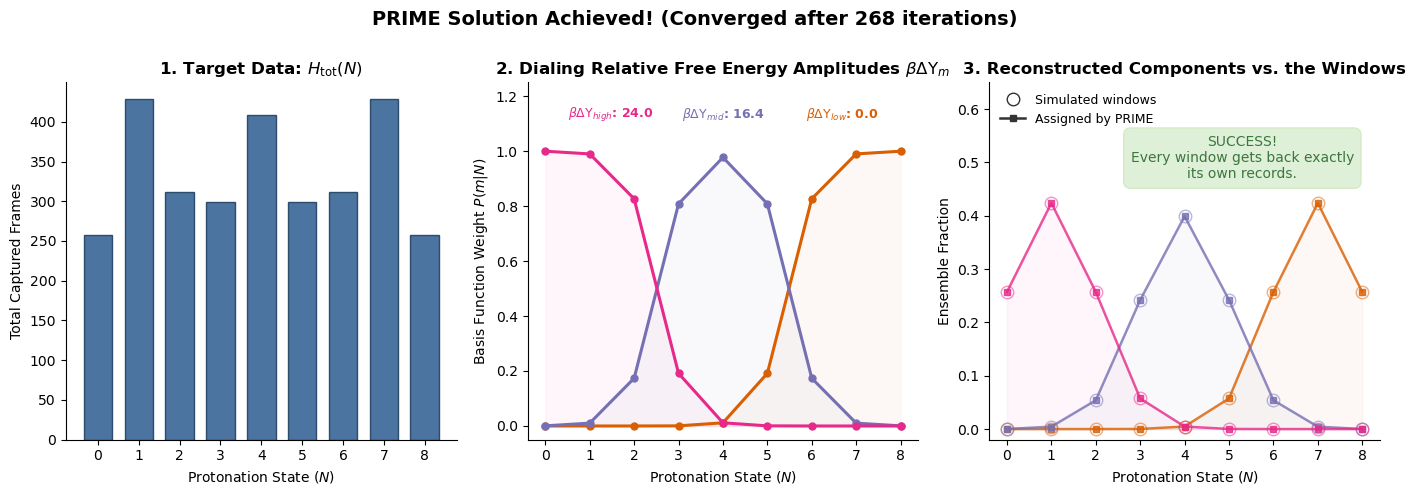

In [3]:
def create_prime_animation_with_sum():
    history, steps = iteration_history(H_demo, pH_demo, mix=0.5)
    n_opt = len(steps)
    num_hold_frames = 20
    M = H_demo.sum(axis=1)

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 5))

    ax1.bar(N_vals, H_tot, color='#2b5c8f', edgecolor='#1a3a5c', width=0.7, alpha=0.85)
    ax1.set_title(r"1. Target Data: $H_{\mathrm{tot}}(N)$", fontsize=12, weight='bold')
    ax1.set_xlabel('Protonation State ($N$)', fontsize=10)
    ax1.set_ylabel('Total Captured Frames', fontsize=10)
    ax1.set_xticks(N_vals)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)

    lines_p2, lines_p3 = [], []
    for color in colors_m:
        line2, = ax2.plot([], [], '-o', color=color, linewidth=2.2, markersize=5)
        lines_p2.append(line2)
        line3, = ax3.plot([], [], '-s', color=color, linewidth=1.8, markersize=4, alpha=0.8)
        lines_p3.append(line3)
    for H, color in zip(H_demo, colors_m):
        ax3.plot(N_vals, H / 1000, 'o', color=color, markersize=9, markerfacecolor='none', alpha=0.5)
    ax3.plot([], [], 'o', color='#333333', markersize=9, markerfacecolor='none', label='Simulated windows')
    ax3.plot([], [], '-s', color='#333333', linewidth=1.8, markersize=4, label='Assigned by PRIME')
    ax3.legend(frameon=False, loc='upper left', fontsize=9)

    iter_text = fig.suptitle('', fontsize=14, weight='bold', y=0.98)
    param_text_high = ax2.text(0.5, 1.12, '', color=colors_m[2], fontsize=9, ha='left', weight='bold')
    param_text_mid = ax2.text(4.0, 1.12, '', color=colors_m[1], fontsize=9, ha='center', weight='bold')
    param_text_low = ax2.text(7.5, 1.12, '', color=colors_m[0], fontsize=9, ha='right', weight='bold')
    status_box = ax3.text(5.3, 0.47, '', bbox=dict(facecolor='#fcf8e3', edgecolor='#faebcc', boxstyle='round,pad=0.5'),
                          fontsize=10, ha='center', color='#8a6d3b')

    ax2.set_title(r"2. Dialing Relative Free Energy Amplitudes $\beta\Delta\Upsilon_m$", fontsize=12, weight='bold')
    ax2.set_xlabel('Protonation State ($N$)', fontsize=10)
    ax2.set_ylabel('Basis Function Weight $P(m|N)$', fontsize=10)
    ax2.set_ylim(-0.05, 1.25)
    ax2.set_xticks(N_vals)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)

    ax3.set_title("3. Reconstructed Components vs. the Windows", fontsize=12, weight='bold')
    ax3.set_xlabel('Protonation State ($N$)', fontsize=10)
    ax3.set_ylabel('Ensemble Fraction', fontsize=10)
    ax3.set_ylim(-0.02, 0.65)
    ax3.set_xticks(N_vals)
    ax3.spines['top'].set_visible(False)
    ax3.spines['right'].set_visible(False)

    plt.tight_layout(rect=[0, 0, 1, 0.94])

    def update(frame):
        for coll in list(ax2.collections) + list(ax3.collections):
            coll.remove()
        it = min(frame, n_opt)
        g = history[it]
        P = assignment(g, H_demo, pH_demo)
        assigned = (H_tot * P).sum(axis=1)                 # records handed to every window

        for i, color in enumerate(colors_m):
            lines_p2[i].set_data(N_vals, P[i])
            ax2.fill_between(N_vals, 0, P[i], color=color, alpha=0.04)
            lines_p3[i].set_data(N_vals, H_tot * P[i] / 1000)
            ax3.fill_between(N_vals, 0, H_tot * P[i] / 1000, color=color, alpha=0.04)

        param_text_low.set_text(f"$\\beta\\Delta\\Upsilon_{{low}}$: {g[0]:.1f}")
        param_text_mid.set_text(f"$\\beta\\Delta\\Upsilon_{{mid}}$: {g[1]:.1f}")
        param_text_high.set_text(f"$\\beta\\Delta\\Upsilon_{{high}}$: {g[2]:.1f}")

        if it < n_opt:
            mismatch = np.abs(assigned - M).sum() / M.sum()
            iter_text.set_text(f"PRIME Optimization Loop — Iteration Step: {it}")
            status_box.set_text(f"Fitting Global Landscape...\nAssigned records: " + ", ".join(f"{a:.0f}" for a in assigned)
                                + f"\nMismatch with $M_k$: {mismatch:.3f}")
            status_box.set_bbox(dict(facecolor='#fcf8e3', edgecolor='#faebcc', boxstyle='round,pad=0.5'))
            status_box.set_color('#8a6d3b')
        else:
            iter_text.set_text(f"PRIME Solution Achieved! (Converged after {n_opt} iterations)")
            status_box.set_text("SUCCESS!\nEvery window gets back exactly\nits own records.")
            status_box.set_bbox(dict(facecolor='#dff0d8', edgecolor='#d6e9c6', boxstyle='round,pad=0.5'))
            status_box.set_color('#3c763d')

        return lines_p2 + lines_p3 + [iter_text, param_text_high, param_text_mid, param_text_low, status_box]

    frames = list(range(0, min(30, n_opt))) + list(range(30, n_opt + 1, 5)) + [n_opt] * num_hold_frames
    ani = animation.FuncAnimation(fig, update, frames=frames, interval=150, blit=False, repeat=True)
    ani.save('Animations/PRIME_full_reconstruction_movie.gif', writer='pillow', fps=8, dpi=100)
    if animation.writers.is_available('ffmpeg'):
        ani.save('Animations/PRIME_full_reconstruction_movie.mp4', writer='ffmpeg', fps=8, bitrate=1800, dpi=100)
    return ani


prime_movie_with_sum = create_prime_animation_with_sum()
plt.show()


# 3. Animation: the limit of the method

PRIME relates the windows to each other through the protonation numbers they share. Two windows that both have records at some $N$ fix their potentials relative to each other through $c(N)$, so the free energy between them is determined. Two windows with no $N$ in common are not connected, their relative potential is undetermined, and the equations have no unique solution. The condition is the connectivity of the windows through the sampled protonation numbers (`prime.support_connected`), and the animation shows what happens on the way to that limit.

Three windows of the same width on a molecule with 24 protonation states are moved apart symmetrically. For every separation the fixed-point iteration is run for 150 steps with mixing 0.5, and the size of the last step is the residual. Panel 1 shows the three windows with the pH of each above it and the overlap of neighbors in gray. Panel 2 tracks the residual against the overlap of neighboring windows, in percent of the records, and the dot turns red once the iteration no longer converges. Panel 3 is the iteration itself at the current separation. With ample overlap the residual falls to machine precision within a few dozen steps. As the overlap shrinks the convergence slows, because the relative potential of two windows is fixed by fewer and fewer records, and once the windows share no records at all the iteration stalls in a limit cycle. On a real pH grid the same loss shows up before the break, as a growing statistical error of the free energy across the gap. Section IV D of the manuscript follows it by coarsening the insulin grids, and the prediction from one and two windows in Section IV E requires the connection to survive the block bootstrap, which is what `prime.predict` reports as `connected` and `fragile`.

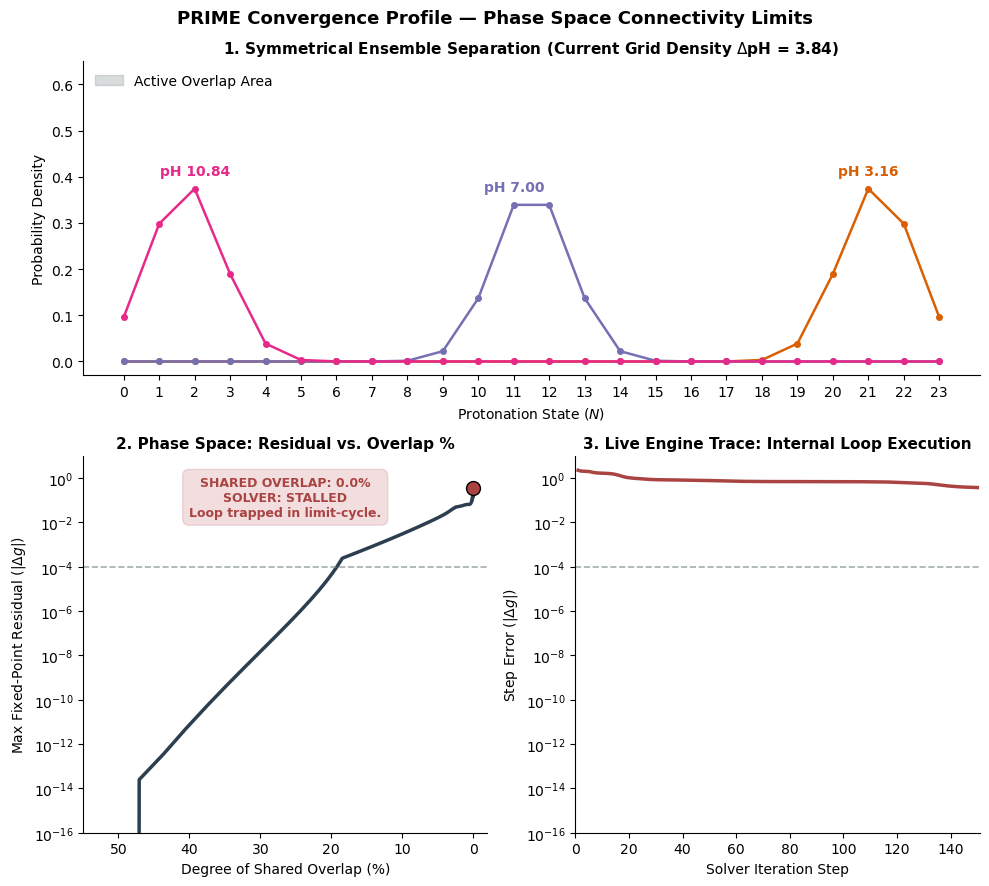

In [4]:
def create_symmetrical_moving_ph_diagnostic():
    fig = plt.figure(figsize=(10, 9))
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.2])
    ax1 = fig.add_subplot(gs[0, :])
    ax2 = fig.add_subplot(gs[1, 0])
    ax3 = fig.add_subplot(gs[1, 1])

    N24 = np.arange(24)
    colors = ['#d95f02', '#7570b3', '#e7298a']
    width, center_mid, ph_mid, n_iter = 1.05, 11.5, 7.0, 150
    lnc = -(N24 - center_mid) ** 2 / (2 * width ** 2) + ph_mid * LN10 * N24     # middle window centered at N = 11.5

    spacings = np.concatenate([np.linspace(0.4, 2.0, 25), np.linspace(2.01, 4.2, 65), np.linspace(4.21, 6.5, 25)])
    overlap_metrics, final_residuals, histograms_cache, iteration_paths_cache, ph_cache = [], [], [], [], []
    for spacing in spacings:
        delta_ph = 1.5 * spacing / (width ** 2 * LN10)                             # moves the outer centers by 1.5 spacing
        pHs = np.array([ph_mid - delta_ph, ph_mid, ph_mid + delta_ph])
        H = np.array([1000 * prime.distribution(lnc, pH)[1] for pH in pHs])
        p = H / H.sum(axis=1, keepdims=True)
        histograms_cache.append(H)
        ph_cache.append(pHs)
        overlap_metrics.append(0.5 * (np.sum(np.minimum(p[0], p[1])) + np.sum(np.minimum(p[1], p[2]))) * 100)

        g = np.zeros(3)
        frame_iter_history = []
        for _ in range(n_iter):
            g_new = iterate(H, pHs, g, mix=0.5)
            frame_iter_history.append(np.max(np.abs(g_new - g)))
            g = g_new
        final_residuals.append(frame_iter_history[-1])
        iteration_paths_cache.append(frame_iter_history)

    overlap_metrics = np.array(overlap_metrics)
    final_residuals = np.array(final_residuals)

    def update(frame):
        ax1.clear()
        ax2.clear()
        ax3.clear()

        H = histograms_cache[frame]
        pHs = ph_cache[frame]
        current_overlap = overlap_metrics[frame]
        current_res = final_residuals[frame]
        iter_history = iteration_paths_cache[frame]
        delta_ph = pHs[2] - pHs[1]

        p_low, p_mid, p_high = H / 1000.0
        ax1.plot(N24, p_low, '-o', color=colors[0], linewidth=1.8, markersize=4)
        ax1.plot(N24, p_mid, '-o', color=colors[1], linewidth=1.8, markersize=4)
        ax1.plot(N24, p_high, '-o', color=colors[2], linewidth=1.8, markersize=4)
        ax1.fill_between(N24, 0, np.minimum(p_low, p_mid), color='#7f8c8d', alpha=0.3, label='Active Overlap Area')
        ax1.fill_between(N24, 0, np.minimum(p_mid, p_high), color='#7f8c8d', alpha=0.3)
        for p, pH, color in zip((p_low, p_mid, p_high), pHs, colors):
            ax1.text(N24[np.argmax(p)], np.max(p) + 0.03, f"pH {pH:.2f}", color=color, fontsize=10, weight='bold', ha='center')
        ax1.set_title(f"1. Symmetrical Ensemble Separation (Current Grid Density $\\Delta$pH = {delta_ph:.2f})", fontsize=11, weight='bold')
        ax1.set_ylabel("Probability Density", fontsize=10)
        ax1.set_xlabel("Protonation State ($N$)", fontsize=10)
        ax1.set_ylim(-0.03, 0.65)
        ax1.set_xticks(N24)
        ax1.legend(frameon=False, loc='upper left')
        ax1.spines['top'].set_visible(False)
        ax1.spines['right'].set_visible(False)

        sort_idx = np.argsort(overlap_metrics)[::-1]
        ax2.plot(overlap_metrics[sort_idx], final_residuals[sort_idx], color='#bdc3c7', linewidth=1.5, linestyle=':')
        ax2.plot(overlap_metrics[:frame + 1], final_residuals[:frame + 1], color='#2c3e50', linewidth=2.5)
        is_converged = current_res < 1e-4
        dot_color = '#3c763d' if is_converged else '#a94442'
        ax2.plot(current_overlap, current_res, 'o', color=dot_color, markersize=10, markeredgecolor='black')
        ax2.set_title("2. Phase Space: Residual vs. Overlap %", fontsize=11, weight='bold')
        ax2.set_xlabel("Degree of Shared Overlap (%)", fontsize=10)
        ax2.set_ylabel(r"Max Fixed-Point Residual ($|\Delta g|$)", fontsize=10)
        ax2.set_xlim(55, -2)
        ax2.set_yscale('log')
        ax2.set_ylim(1e-16, 10)
        ax2.axhline(1e-4, color='#7f8c8d', linestyle='--', linewidth=1.2, alpha=0.7)
        ax2.spines['top'].set_visible(False)
        ax2.spines['right'].set_visible(False)

        ax3.plot(np.arange(1, n_iter + 1), iter_history, color=dot_color, linewidth=2.5)
        ax3.set_title("3. Live Engine Trace: Internal Loop Execution", fontsize=11, weight='bold')
        ax3.set_xlabel("Solver Iteration Step", fontsize=10)
        ax3.set_ylabel(r"Step Error ($|\Delta g|$)", fontsize=10)
        ax3.set_yscale('log')
        ax3.set_ylim(1e-16, 10)
        ax3.set_xlim(0, n_iter + 1)
        ax3.axhline(1e-4, color='#7f8c8d', linestyle='--', linewidth=1.2, alpha=0.7)
        ax3.spines['top'].set_visible(False)
        ax3.spines['right'].set_visible(False)

        if is_converged:
            status_text = f"SHARED OVERLAP: {current_overlap:.1f}%\nSOLVER: SUCCESS\nError dives to machine zero."
            bg_color, border_color, text_color = '#dff0d8', '#d6e9c6', '#3c763d'
        else:
            status_text = f"SHARED OVERLAP: {current_overlap:.1f}%\nSOLVER: STALLED\nLoop trapped in limit-cycle."
            bg_color, border_color, text_color = '#f2dede', '#ebccd1', '#a94442'
        ax2.text(26.5, 2e-2, status_text, bbox=dict(facecolor=bg_color, edgecolor=border_color, boxstyle='round,pad=0.5'),
                 fontsize=9, ha='center', color=text_color, weight='bold')

        fig.suptitle("PRIME Convergence Profile — Phase Space Connectivity Limits", fontsize=13, weight='bold', y=0.98)
        plt.tight_layout()

    ani = animation.FuncAnimation(fig, update, frames=len(spacings), interval=140, repeat=True)
    ani.save('Animations/PRIME_symmetrical_moving_ph.gif', writer='pillow', fps=8, dpi=100)
    if animation.writers.is_available('ffmpeg'):
        ani.save('Animations/PRIME_symmetrical_moving_ph.mp4', writer='ffmpeg', fps=8, bitrate=1800, dpi=100)
    plt.show()
    return ani


create_symmetrical_moving_ph_diagnostic()


# 4. Animation: window bias from a slow degree of freedom

Sections 1 to 3 took every window to be a faithful sample of the molecule at its pH. In the semi-grand ensemble that means that the time average of a window equals the ensemble average at its pH, which holds when the run is ergodic over the simulated time. A degree of freedom that is coupled to the protonation and relaxes more slowly than the run is long breaks this. The window then samples the environment it started in, or the one its own pH has pushed it into, and not the equilibrium mixture of environments, and two windows at different pH keep different environments. Their records are no longer samples of one and the same $c(N)$. This is non-ergodicity within the simulated time. Hysteresis in a pH titration, where the result depends on the direction in which the pH was swept, is the same effect seen through the starting structures of the windows.

The consistency test of the manuscript (Section IV F, Eq. 25) looks for exactly this. The stepwise $\mathrm{p}K_N$,

$$\mathrm{p}K_N = \log_{10} \frac{\Pr(N \mid k)}{\Pr(N-1 \mid k)} + \mathrm{pH}_k = \log_{10}\frac{c(N)}{c(N-1)} ,$$

is a property of the molecule and not of the window, because the pH cancels. Every window that has records at both $N-1$ and $N$ measures it. Plotted against the pH of the window, the values of a step lie on a horizontal line if the windows sample the same molecule, and windows that keep different environments give a line with a slope, a step or a curve in it. The test uses nothing but the sampled histograms, so it is independent of the free-energy estimate, and `prime.consistency_test` reports for every step the weighted mean of the windows and their spread beyond the statistical errors, $\tau$.

The three animations of this section show the mechanism in the smallest model that has it, one titratable site with a hidden slow conformation, and they show the test seeing it.

**The two-state model.** One titratable site sits in a molecule with two conformations. In conformation A the site has $\mathrm{p}K_\mathrm{a}$ 4.0, in conformation B 5.0, and B is favored 3.2 to 1 when the site is protonated and disfavored by the same factor when it is not. At equilibrium the site titrates with $\mathrm{p}K_\mathrm{a}$ 4.5. Sixteen pH windows are simulated, from pH 3.0 to 6.0 in steps of 0.2. Every step the protonation is resampled given the conformation, and with a small probability per step the conformation attempts a Metropolis switch given the protonation. Each window starts in the conformation that its own pH favors.

Left, the last 400 steps of every other window, the protonation as the line and the conformation as the background. Right, the test with all sixteen windows. The $\mathrm{p}K_\mathrm{a}$ that each window has measured from its records so far, $\log_{10}$ of the protonated over the deprotonated count plus the pH, is plotted against the pH of the window, with the point colored by the conformation of its records. If the windows sample the same molecule the points fall on one horizontal line. With a conformation that is too slow to switch within the run (top) each window stays in its conformation and measures the $\mathrm{p}K_\mathrm{a}$ of that conformation, 5.0 below pH 4.5 and 4.0 above. A window in one conformation measures nothing in between, so the line has a sharp step at pH 4.5, and more steps only sharpen it. With a conformation that switches every few steps (bottom) all sixteen windows settle on the line at 4.5.

A conformation too slow to switch within the run: conformation switches per window [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
A conformation that switches every few steps: conformation switches per window [462 454 512 485 501 453 473 475 462 480 477 448 506 488 483 484]


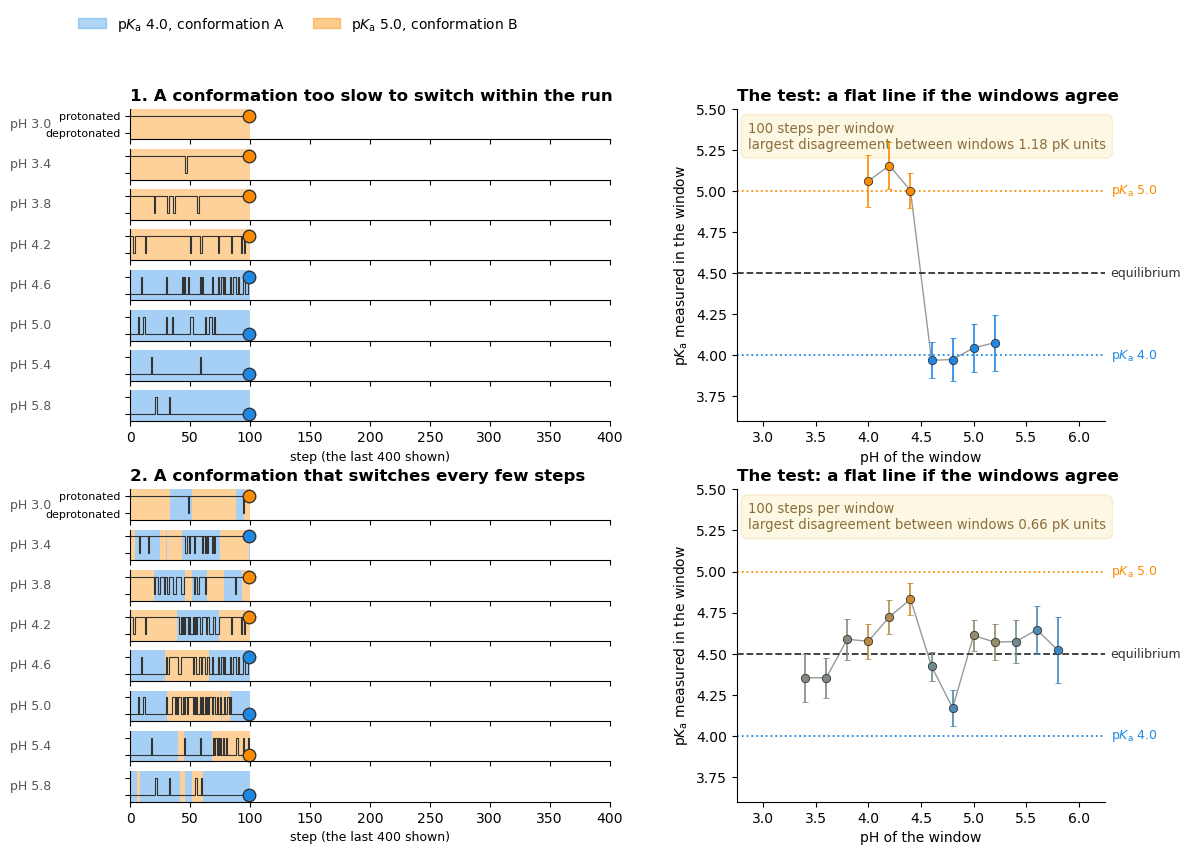

In [5]:
from matplotlib.colors import to_rgb, LinearSegmentedColormap

pKa_s = np.array([4.0, 5.0])        # pKa of the site in conformation A and B
eps_s = 0.5 * LN10                  # cost of B when the site is deprotonated, gain when it is protonated
pH_w = np.round(np.arange(3.0, 6.01, 0.2), 1)
K1, T1, W1 = len(pH_w), 10000, 400
pK_two = np.log10((10 ** pKa_s[0] + np.exp(-eps_s) * 10 ** pKa_s[1]) / (1 + np.exp(-eps_s)))
col_s = ['#1e88e5', '#fb8c00']
cmap_s = LinearSegmentedColormap.from_list('AB', col_s)


def simulate_two_state(rate, seed=1, T=T1):
    '''Protonation n(t) and conformation s(t), 0 for A and 1 for B, of every window over T steps.'''
    rng = np.random.default_rng(seed)
    s = (pH_w < pK_two).astype(int)             # each window starts in the conformation its pH favors
    nrec, srec = np.empty((K1, T), dtype=np.int8), np.empty((K1, T), dtype=np.int8)
    for t in range(T):
        n = (rng.random(K1) < 1.0 / (1.0 + 10 ** (pH_w - pKa_s[s]))).astype(int)
        dE = (1 - 2 * s) * (eps_s - LN10 * (pKa_s[1] - pKa_s[0]) * n)
        flip = (rng.random(K1) < rate) & (rng.random(K1) < np.exp(-np.clip(dE, 0, None)))
        s = np.where(flip, 1 - s, s)
        nrec[:, t], srec[:, t] = n, s
    return nrec, srec


def running_pK(nrec, srec):
    '''After every step, the pKa each window has measured from its counts so far, its counting error, and the
    mean conformation of its records.'''
    H1 = np.cumsum(nrec, axis=1, dtype=np.int64)
    H0 = np.arange(1, T1 + 1) - H1
    ok = (H0 >= 5) & (H1 >= 5)
    with np.errstate(divide='ignore', invalid='ignore'):
        pK = np.where(ok, np.log10(H1 / H0) + pH_w[:, None], np.nan)
        se = np.where(ok, np.sqrt(1.0 / H1 + 1.0 / H0) / LN10, np.nan)
    return pK, se, np.cumsum(srec, axis=1, dtype=np.float64) / np.arange(1, T1 + 1)


def test_panel(ax, pK_eq, ends):
    '''The test panel without its points. Returns the text box of the panel.'''
    ax.axhline(pKa_s[0], color=col_s[0], linestyle=':', linewidth=1.3)
    ax.axhline(pKa_s[1], color=col_s[1], linestyle=':', linewidth=1.3)
    ax.axhline(pK_eq, color='#333333', linestyle='--', linewidth=1.3)
    for y, label, c in [(pKa_s[0], ends[0], col_s[0]), (pKa_s[1], ends[1], col_s[1]), (pK_eq, 'equilibrium', '#333333')]:
        ax.text(pH_w[-1] + 0.3, y, label, va='center', fontsize=9, color=c)
    ax.set_xlim(pH_w[0] - 0.25, pH_w[-1] + 0.25)
    ax.set_xticks(np.arange(pH_w[0], pH_w[-1] + 0.01, 0.5))
    ax.set_ylim(3.6, 5.5)
    ax.set_xlabel("pH of the window", fontsize=10)
    ax.set_ylabel(r"p$K_\mathrm{a}$ measured in the window", fontsize=10)
    ax.set_title("The test: a flat line if the windows agree", fontsize=12, weight='bold', loc='left')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    return ax.text(0.03, 0.96, '', transform=ax.transAxes, va='top', fontsize=9.5, color='#8a6d3b',
                   bbox=dict(facecolor='#fcf8e3', edgecolor='#faebcc', boxstyle='round,pad=0.5'))


def test_points(ax, pK, se, fB):
    '''The points of the test panel for one length of the run. Returns the artists and the largest disagreement.'''
    ok = np.isfinite(pK)
    art = ax.plot(pH_w[ok], pK[ok], '-', color='#999999', linewidth=1.0, zorder=1)
    for k in np.flatnonzero(ok):
        art.append(ax.errorbar(pH_w[k], pK[k], yerr=se[k], fmt='o', color=cmap_s(float(fB[k])), markeredgecolor='#333333',
                               markeredgewidth=0.6, markersize=6, elinewidth=1.2, capsize=2.5, zorder=3))
    return art, (np.ptp(pK[ok]) if ok.sum() >= 2 else np.nan)


def window_bias_movie(runs, pK_eq, name, ends):
    '''Two rows, one per run in runs, with the strips of every other window on the left and the test on the right.
    Saved under Animations/name. Returns the running estimates of the runs.'''
    est = [running_pK(nrec, srec) for _, (nrec, srec) in runs]
    ks = np.arange(0, K1, 2)
    fig = plt.figure(figsize=(13, 9))
    gs = fig.add_gridspec(2 * len(ks) + 1, 2, width_ratios=[1.3, 1], height_ratios=[1] * len(ks) + [1.6] + [1] * len(ks),
                          hspace=0.3, wspace=0.3, left=0.15)
    strips, panels, boxes = [], [], []
    for r, (title, (nrec, srec)) in enumerate(runs):
        row = [fig.add_subplot(gs[(len(ks) + 1) * r + i, 0]) for i in range(len(ks))]
        for i, ax in enumerate(row):
            ax.set_ylim(-0.4, 1.4)
            ax.set_yticks([0, 1])
            ax.set_yticklabels(['deprotonated', 'protonated'] if i == 0 else [], fontsize=8)
            ax.set_ylabel(f"pH {pH_w[ks[i]]}", fontsize=9, color='#555555', rotation=0, ha='right', va='center')
            ax.yaxis.set_label_coords(-0.165, 0.5)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            if i == 0:
                ax.set_title(title, fontsize=12, weight='bold', loc='left')
            if i < len(ks) - 1:
                ax.tick_params(labelbottom=False)
            else:
                ax.set_xlabel("step (the last 400 shown)", fontsize=9)
        strips.append(row)
        ax = fig.add_subplot(gs[(len(ks) + 1) * r:(len(ks) + 1) * r + len(ks), 1])
        panels.append(ax)
        boxes.append(test_panel(ax, pK_eq, ends))
    fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=col_s[0], alpha=0.35, label=f'{ends[0]}, conformation A'),
                        plt.Rectangle((0, 0), 1, 1, color=col_s[1], alpha=0.45, label=f'{ends[1]}, conformation B')],
               frameon=False, loc='lower left', bbox_to_anchor=(0.1, 0.95), fontsize=10, ncol=2, columnspacing=2.0)
    artists = []

    def update(t):
        for a in artists:
            a.remove()
        artists.clear()
        lo = max(0, t - W1)
        x = np.arange(lo, t)
        for r, (title, (nrec, srec)) in enumerate(runs):
            for i, ax in enumerate(strips[r]):
                k = ks[i]
                artists.append(ax.imshow(srec[k, None, lo:t], extent=(lo, t, -0.4, 1.4), aspect='auto', cmap=cmap_s,
                                         vmin=0, vmax=1, alpha=0.4, interpolation='nearest'))
                artists.extend(ax.step(x, nrec[k, lo:t], where='post', color='#333333', linewidth=0.8))
                artists.extend(ax.plot(t - 1, nrec[k, t - 1], 'o', markersize=9, color=cmap_s(float(srec[k, t - 1])),
                                       markeredgecolor='#333333', clip_on=False))
                ax.set_xlim(lo, max(t, W1))
                ax.set_ylim(-0.4, 1.4)
            art, spread = test_points(panels[r], *(a[:, t - 1] for a in est[r]))
            artists.extend(art)
            boxes[r].set_text(f"{t} steps per window" + ("" if np.isnan(spread) else f"\nlargest disagreement between windows {spread:.2f} pK units"))
        return artists + boxes

    frames = list(range(100, T1 + 1, 100)) + [T1] * 20
    ani = animation.FuncAnimation(fig, update, frames=frames, interval=125, blit=False, repeat=True)
    ani.save(f'Animations/{name}.gif', writer='pillow', fps=8, dpi=100)
    if animation.writers.is_available('ffmpeg'):
        ani.save(f'Animations/{name}.mp4', writer='ffmpeg', fps=8, bitrate=1800, dpi=100)
    update(T1)
    fig.savefig(f'Animations/{name}.png', dpi=200, bbox_inches='tight')
    return est


runs_two = [("1. A conformation too slow to switch within the run", simulate_two_state(1.0e-6)),
            ("2. A conformation that switches every few steps", simulate_two_state(0.1))]
for title, (nrec, srec) in runs_two:
    print(f"{title[3:]}: conformation switches per window {np.abs(np.diff(srec, axis=1)).sum(axis=1).astype(int)}")
est_two = window_bias_movie(runs_two, pK_two, 'PRIME_slow_conformation', (r'p$K_\mathrm{a}$ 4.0', r'p$K_\mathrm{a}$ 5.0'))


**A conformation that can sit anywhere between A and B.** The coordinate $x$ costs $\kappa x^2/2$ with $\kappa = \ln 10$, the site has $\mathrm{p}K_\mathrm{a}$ $4 + x$, and protonation pulls the coordinate toward larger $x$ by $x \ln 10$, so the favored $x$ is 1 while the site is protonated, 0 while it is not, and in between for a window whose site is protonated part of the time. At equilibrium the site again titrates with $\mathrm{p}K_\mathrm{a}$ 4.5. A coordinate that is frozen at the value its pH favors (top) gives the windows a curve instead of a step, 5.0 at low pH, 4.0 at high pH and steepest at pH 4.5. A curve of this kind, and not a flat line, is what the test shows when the windows keep different environments, and the shape of the curve tells whether the slow degree of freedom has a few states or a continuum. A coordinate that moves every few steps (bottom) gives the flat line.

A coordinate frozen where its pH put it: moves of the coordinate per window [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
A coordinate that moves every few steps: moves of the coordinate per window [7685 7682 7720 7706 7731 7719 7729 7674 7643 7617 7708 7715 7678 7737
 7698 7719]


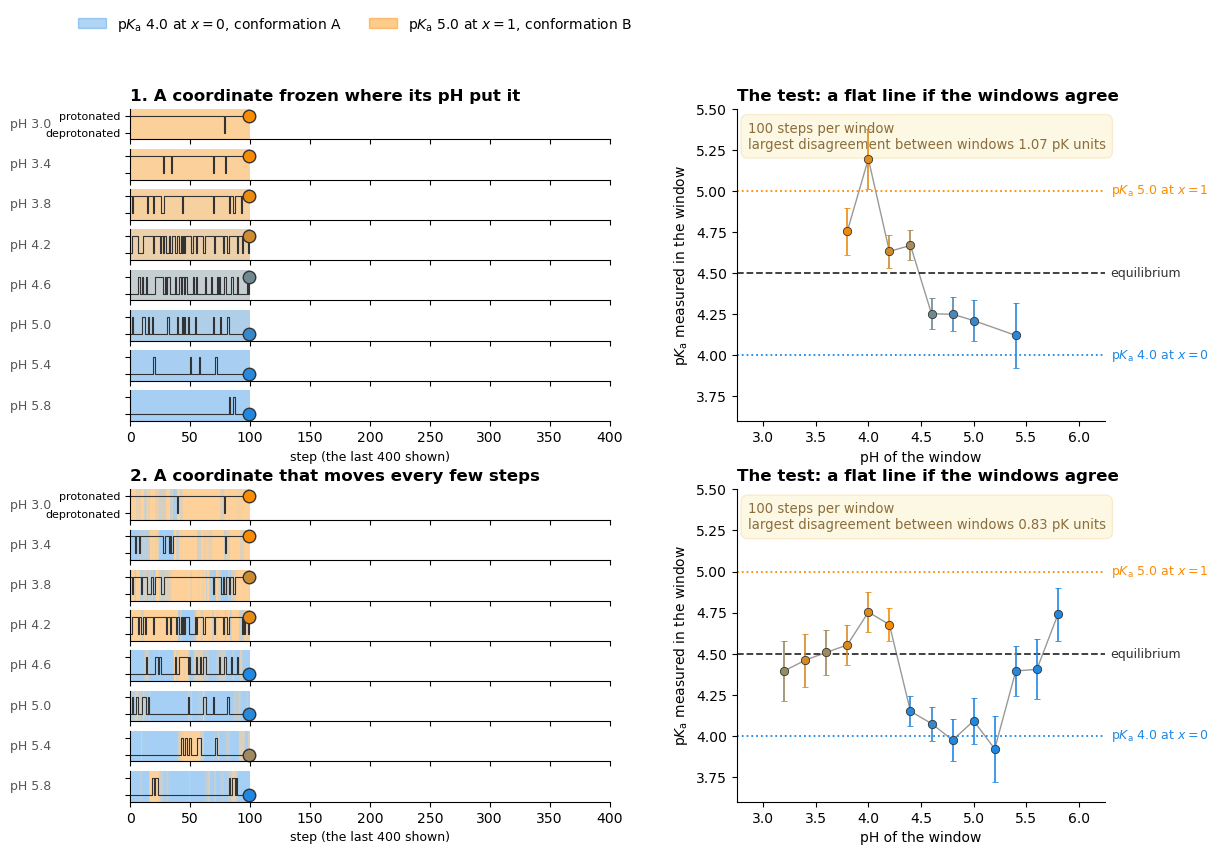

In [6]:
kappa = LN10
pK_soft = pKa_s[0] + LN10 / (2 * kappa)


def favored_x(pH):
    '''The minimum of the free energy of the coordinate at pH, by iteration.'''
    x = np.full(len(pH), 0.5)
    for _ in range(200):
        x = (LN10 / kappa) / (1.0 + 10 ** (pH - pKa_s[0] - x))
    return x


def simulate_soft(rate, seed=1, step=0.5):
    '''Protonation n(t) and coordinate x(t) of every window, with Gaussian Metropolis moves of the coordinate.'''
    rng = np.random.default_rng(seed)
    x = favored_x(pH_w)
    nrec, xrec = np.empty((K1, T1), dtype=int), np.empty((K1, T1))
    for t in range(T1):
        n = (rng.random(K1) < 1.0 / (1.0 + 10 ** (pH_w - pKa_s[0] - x))).astype(int)
        y = x + step * rng.standard_normal(K1)
        dE = 0.5 * kappa * (y ** 2 - x ** 2) - LN10 * (y - x) * n
        move = (rng.random(K1) < rate) & (rng.random(K1) < np.exp(-np.clip(dE, 0, None)))
        x = np.where(move, y, x)
        nrec[:, t], xrec[:, t] = n, x
    return nrec, xrec


runs_soft = [("1. A coordinate frozen where its pH put it", simulate_soft(1.0e-6)),
             ("2. A coordinate that moves every few steps", simulate_soft(1.0))]
for title, (nrec, xrec) in runs_soft:
    print(f"{title[3:]}: moves of the coordinate per window {(np.diff(xrec, axis=1) != 0).sum(axis=1)}")
est_soft = window_bias_movie(runs_soft, pK_soft, 'PRIME_slow_conformation_soft', (r'p$K_\mathrm{a}$ 4.0 at $x = 0$', r'p$K_\mathrm{a}$ 5.0 at $x = 1$'))


**Window bias is a matter of time.** Non-ergodicity within the simulated time is a property of the run, not of the molecule. The same two-state model with a conformation that switches about once every 8000 steps is followed for three million steps and shown on a logarithmic clock. Top left, the conformation of every window over the run, with the share of B in each stretch of time as the color. Bottom left, the largest disagreement between windows and $\tau$, the spread of the windows beyond their statistical errors as `prime.consistency_test` reports it. Right, the test at the current length of the run, with the errors from the block bootstrap of `prime`. Up to a few thousand steps the windows are still in their starting conformations and the step is there. Once the conformation has switched a few times in every window the points move toward the line. When every window has switched hundreds of times the windows agree within their statistical errors and $\tau$ has fallen to a few hundredths of a pK unit. What removes the bias is the number of switches, not the number of steps as such. A run can be long and still biased when a degree of freedom coupled to the protonation is slow, and the test tells the two cases apart from the records alone, without knowing what the slow degree of freedom is.

switches per window over the run: 291 on average, at the end the windows disagree by 0.12 pK units with errors up to 0.03 and tau 0.030


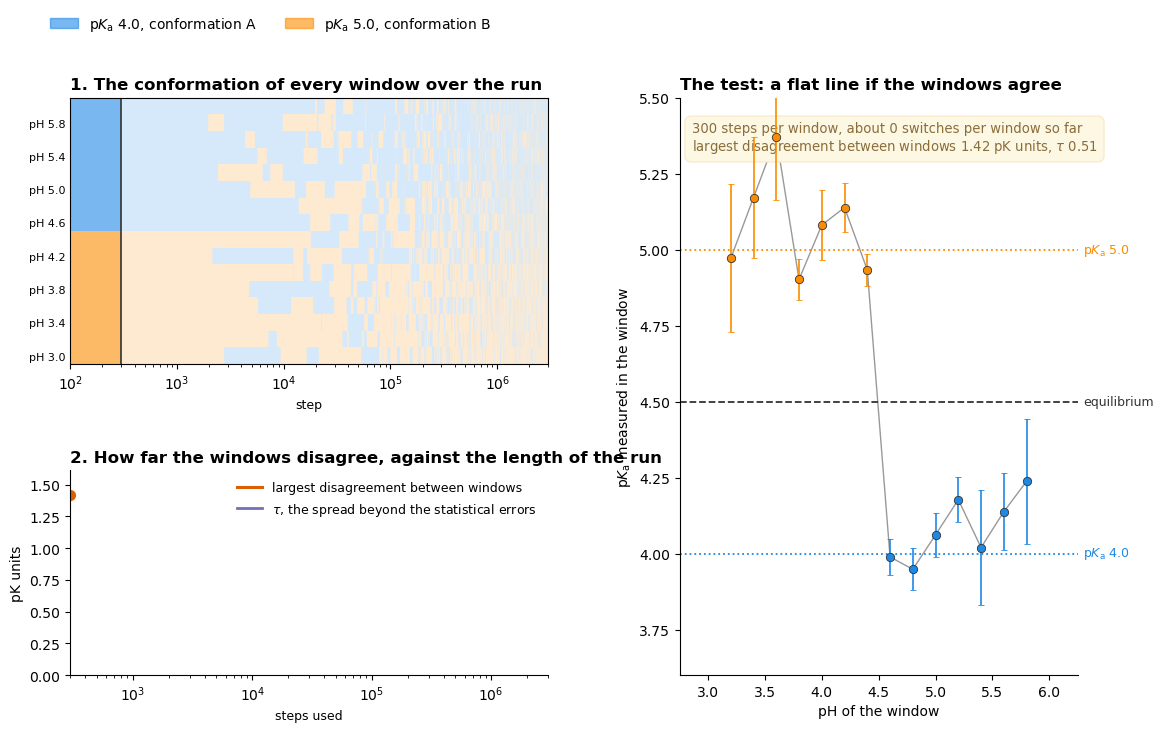

In [7]:
T3 = 3_000_000
nrec3, srec3 = simulate_two_state(2.0e-4, T=T3)
times3 = np.unique(np.logspace(np.log10(300), np.log10(T3), 120).astype(int))
times3[-1] = T3


def counts_at(rec, times):
    '''Cumulative sums of rec along the run at the given times, without the full cumulative array.'''
    return np.cumsum(np.add.reduceat(rec, np.concatenate([[0], times[:-1]]), axis=1, dtype=np.int64), axis=1)




def test_at(t, n_blocks=20):
    '''The consistency test of prime on the first t steps of every window, with errors from its block bootstrap.'''
    edges = np.linspace(0, t, n_blocks + 1).astype(int)
    h1 = np.add.reduceat(nrec3[:, :t], edges[:-1], axis=1, dtype=np.int64)
    h_blk = np.stack([np.diff(edges) - h1, h1], axis=2)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", prime.PRIMEWarning)
        return prime.consistency_test(h_blk.sum(axis=1), pH_w, h_blk, n_boot=200, min_count=5, max_se=5.0)


res3 = [test_at(t) for t in times3]
pK3 = np.array([r["pK"][:, 0] for r in res3]).T
se3 = np.array([r["se"][:, 0] for r in res3]).T
tau3 = np.array([r["tau"][0] for r in res3])
fB3 = counts_at(srec3, times3) / times3
switches3 = counts_at(np.abs(np.diff(srec3, axis=1)), times3 - 1).mean(axis=0)
spread3 = np.nanmax(pK3, axis=0) - np.nanmin(pK3, axis=0)
print(f"switches per window over the run: {switches3[-1]:.0f} on average, at the end the windows disagree by {spread3[-1]:.2f} pK units "
      f"with errors up to {np.nanmax(se3[:, -1]):.2f} and tau {tau3[-1]:.3f}")

# the share of B in log-spaced stretches of the run, for the history panel
edges3 = np.unique(np.logspace(2, np.log10(T3), 400).astype(int))
share3 = np.diff(counts_at(srec3, edges3), axis=1) / np.diff(edges3)

fig = plt.figure(figsize=(13, 7.5))
gs = fig.add_gridspec(2, 2, width_ratios=[1.2, 1], height_ratios=[1.3, 1], hspace=0.45, wspace=0.3)
ax_hist = fig.add_subplot(gs[0, 0])
ax_hist.pcolormesh(edges3, np.arange(K1 + 1), share3, cmap=cmap_s, vmin=0, vmax=1, alpha=0.6, shading='flat', rasterized=True)
ax_hist.set_xscale('log')
ax_hist.set_xlim(edges3[0], T3)
ax_hist.set_yticks(np.arange(0, K1, 2) + 0.5)
ax_hist.set_yticklabels([f"pH {pH}" for pH in pH_w[::2]], fontsize=8)
ax_hist.tick_params(axis='y', length=0)
ax_hist.set_xlabel("step", fontsize=9)
ax_hist.set_title("1. The conformation of every window over the run", fontsize=12, weight='bold', loc='left')
cursor = ax_hist.axvline(times3[0], color='#333333', linewidth=1.2)
ax_dis = fig.add_subplot(gs[1, 0])
ax_dis.set_xscale('log')
ax_dis.set_xlim(times3[0], T3)
ax_dis.set_ylim(0, 1.1 * np.nanmax(spread3))
ax_dis.set_xlabel("steps used", fontsize=9)
ax_dis.set_ylabel("pK units", fontsize=10)
ax_dis.set_title("2. How far the windows disagree, against the length of the run", fontsize=12, weight='bold', loc='left')
ax_dis.spines['top'].set_visible(False)
ax_dis.spines['right'].set_visible(False)
line_sp, = ax_dis.plot([], [], '-', color='#d95f02', linewidth=2.2, label='largest disagreement between windows')
line_er, = ax_dis.plot([], [], '-', color='#7570b3', linewidth=2.0, label=r'$\tau$, the spread beyond the statistical errors')
dot_sp, = ax_dis.plot([], [], 'o', color='#d95f02', markersize=7)
ax_dis.legend(frameon=False, loc='upper right', fontsize=9)
ax_test = fig.add_subplot(gs[:, 1])
box3 = test_panel(ax_test, pK_two, (r'p$K_\mathrm{a}$ 4.0', r'p$K_\mathrm{a}$ 5.0'))
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=col_s[0], alpha=0.6, label=r'p$K_\mathrm{a}$ 4.0, conformation A'),
                    plt.Rectangle((0, 0), 1, 1, color=col_s[1], alpha=0.6, label=r'p$K_\mathrm{a}$ 5.0, conformation B')],
           frameon=False, loc='lower left', bbox_to_anchor=(0.1, 0.95), fontsize=10, ncol=2, columnspacing=2.0)
artists = []


def update(i):
    for a in artists:
        a.remove()
    artists.clear()
    t = times3[i]
    cursor.set_xdata([t, t])
    artists.append(ax_hist.axvspan(t, T3, color='white', alpha=0.7, linewidth=0))
    line_sp.set_data(times3[:i + 1], spread3[:i + 1])
    line_er.set_data(times3[:i + 1], tau3[:i + 1])
    dot_sp.set_data([t], [spread3[i]])
    art, spread = test_points(ax_test, pK3[:, i], se3[:, i], fB3[:, i])
    artists.extend(art)
    box3.set_text(f"{t:,} steps per window, about {switches3[i]:.0f} switches per window so far\n"
                  f"largest disagreement between windows {spread:.2f} pK units, $\\tau$ {tau3[i]:.2f}")
    return artists + [cursor, line_sp, line_er, dot_sp, box3]


frames = list(range(len(times3))) + [len(times3) - 1] * 20
ani = animation.FuncAnimation(fig, update, frames=frames, interval=125, blit=False, repeat=True)
ani.save('Animations/PRIME_bias_vs_sampling.gif', writer='pillow', fps=8, dpi=100)
if animation.writers.is_available('ffmpeg'):
    ani.save('Animations/PRIME_bias_vs_sampling.mp4', writer='ffmpeg', fps=8, bitrate=1800, dpi=100)
update(len(times3) - 1)
fig.savefig('Animations/PRIME_bias_vs_sampling.png', dpi=200, bbox_inches='tight')


# 5. Animation: the consequence for the free energy

Section 4 showed the mechanism and the test on one site, where there is a single step and the $\mathrm{p}K_\mathrm{a}$ is the whole story. The quantity the manuscript is after is the free energy between pH values, and that needs a molecule with several sites, where the test has one line per step and the bias of the windows passes through the estimator into $\beta\Delta\Upsilon$. This section is the same mechanism with that consequence. It is also the form of the test used in Fig. 6 of the manuscript, one line per step and the windows plotted as their deviation from the weighted mean of the windows that measure the step.

Two estimators are compared on the same windows. PRIME solves the equations of Section 1 on the histograms of the windows (`prime.solve_prime`). Thermodynamic integration uses the mean protonation number of every window, since

$$\beta\Delta\Upsilon(\mathrm{pH}_2) - \beta\Delta\Upsilon(\mathrm{pH}_1) = \ln 10 \int_{\mathrm{pH}_1}^{\mathrm{pH}_2} \langle N \rangle\, d\mathrm{pH} ,$$

evaluated on the windows by the trapezoidal rule (`prime.compute_TI_trapezoid`). Both take the sampled histograms as they are. A window that keeps the environment of its own pH hands both estimators the same records. The bias is in the records and not in the estimator, and the animation shows what each estimator makes of it.

**The model.** Four identical acidic sites ($\mathrm{p}K_\mathrm{a}$ 4.0) are coupled to a hidden two-state conformation. Conformation B raises the $\mathrm{p}K_\mathrm{a}$ to 5.0 and costs $\epsilon$, so it is favored once three or four sites are protonated and disfavored below that. The sites relax within a few frames. The conformation does not switch within the run, and every window starts in the conformation that its own pH favors. Four windows at pH 2.5, 3.5, 4.5 and 5.5 are simulated for 30000 frames, and the free energy between the outermost windows is estimated from the first $t$ frames of every window as $t$ grows.

Left, the trajectories of the four windows, colored by the hidden conformation. The records up to the cursor are the ones in use. Next to them, on a log scale, the histograms of $N$ that each window has accumulated, split by the conformation in which the records were taken. A step enters the test once both of its protonation numbers have 30 records in a window (dotted line) and its error stays below 0.5 pK units. A window at low pH holds many protons, sits in B and samples its rare protonation numbers in B as well. A window at high pH sits in A. The same step, $2 \rightarrow 3$, is therefore measured in B by the window at pH 3.5 and in A by the window at pH 4.5.

Right, the test. The $\mathrm{p}K_N$ measured in every window is plotted against the pH of the window, as the deviation from the weighted mean of the windows that measure the step, because that spread is all the test can see. Each point is colored by the conformation of its records and carries the block-bootstrap error of `prime`. The points of a step would lie on their line if the windows sampled the same configurations at each $N$. The bracket marks the largest disagreement, and the triangle at the left edge marks the exact $\mathrm{p}K_N$, which only a toy model knows. The line of the step $1 \rightarrow 2$ is flat because only windows in A reach it, and its triangle sits slightly above the line. The test can only compare the windows that overlap on a step. Bottom, the consequence for the free energy between the outermost windows. PRIME and TI both settle about one $k_\mathrm{B}T$ below the exact value, and more frames do not bring them back. The dotted line is TI evaluated with the exact window averages, the part of its error that the trapezoidal rule costs on this grid even with perfect sampling. Section S2 of the SI says how to read the rest. The deviation of a window from its converged histogram has two parts. The part that all windows share changes the aggregated histogram and enters the free energy of every estimator alike. The part in which the windows differ is the residual, which the test displays and which only TI integrates. Here the window at pH 4.5 stays in A for the whole run although it should spend a quarter of its time in B, so the aggregated histogram is wrong and both estimators are wrong by the same $1.1\ k_\mathrm{B}T$. The residual is large and the test shows it, but it is carried by the two inner windows with equal and opposite first moments, because the residual moments of equally long windows sum to zero, so the trapezoidal rule cancels them and the difference between TI and PRIME is the quadrature error alone. The last cell of this section puts numbers on the split.


In [8]:
from matplotlib.colors import to_rgb

pKa_A, shift, n_acid, q_site = 4.0, 1.0, 4, 0.2
eps = 2.5 * LN10 * shift
pHs_c = np.array([2.5, 3.5, 4.5, 5.5])
K = len(pHs_c)
T = 30000
min_count = 30
n_arr = np.arange(n_acid + 1)
wA = np.array([1, 4, 6, 4, 1]) * 10.0 ** (pKa_A * n_arr)
wB = np.array([1, 4, 6, 4, 1]) * 10.0 ** ((pKa_A + shift) * n_arr) * np.exp(-eps)
c_eq = wA + wB
pK_eq = np.log10(c_eq[1:] / c_eq[:-1])
dU_eq, mean_eq, var_eq = prime.reweight(np.log(c_eq), pHs_c)
dU_eq = dU_eq[-1] - dU_eq[0]
# TI from the exact window averages, so the error of the trapezoidal rule on this grid is known on its own
dU_ti_eq = prime.compute_TI_trapezoid(pHs_c, mean_eq, var_eq, np.full(K, T))[0][-1]
colors_s = {0: '#1e88e5', 1: '#fb8c00'}
names_s = {0: r'conformation A (p$K_\mathrm{a}$ 4.0)', 1: r'conformation B (p$K_\mathrm{a}$ 5.0)'}
rgb_s = np.array([to_rgb(colors_s[sv]) for sv in (0, 1)])


def simulate_with_conformation(rate, seed=3):
    '''N(t) and the conformation s(t) of every window. Each site is resampled with probability q_site per frame given
    the conformation, and the conformation attempts a Metropolis flip with probability rate per frame given the sites.'''
    rng = np.random.default_rng(seed)
    pB = np.array([(wB * 10.0 ** (-n_arr * pH)).sum() / (c_eq * 10.0 ** (-n_arr * pH)).sum() for pH in pHs_c])
    s = (rng.random(K) < pB).astype(int)
    sites = rng.random((K, n_acid)) < 1.0 / (1.0 + 10 ** (pHs_c - pKa_A - shift * s))[:, None]
    Nrec, srec = np.empty((K, T), dtype=np.int64), np.empty((K, T), dtype=np.int64)
    for t in range(T):
        p = 1.0 / (1.0 + 10 ** (pHs_c - pKa_A - shift * s))[:, None]
        upd = rng.random((K, n_acid)) < q_site
        sites = np.where(upd, rng.random((K, n_acid)) < p, sites)
        n = sites.sum(axis=1)
        dE = (1 - 2 * s) * (eps - LN10 * shift * n)
        flip = (rng.random(K) < rate) & (rng.random(K) < np.exp(-np.clip(dE, 0, None)))
        s = np.where(flip, 1 - s, s)
        Nrec[:, t], srec[:, t] = n, s
    return Nrec, srec


def running_estimates(Nrec, srec, t):
    '''Everything the panels need from the first t frames of every window.'''
    rec = [Nrec[k, :t] for k in range(K)]
    H = prime.build_histograms(rec, pHs_c, n_sites=n_acid).astype(float)
    h_blk = prime.block_histograms(rec, pHs_c, n_blocks=20, n_sites=n_acid)
    pK, se, usable = prime.stepwise_pka(H, pHs_c, h_blk, n_boot=200, min_count=min_count, max_se=0.5)
    H_by_s = np.array([[np.bincount(Nrec[k, :t][srec[k, :t] == sv], minlength=n_acid + 1) for sv in (0, 1)] for k in range(K)])
    with np.errstate(divide='ignore', invalid='ignore'):
        frac_B = (H_by_s[:, 1, 1:] + H_by_s[:, 1, :-1]) / (H[:, 1:] + H[:, :-1])
        w = np.where(usable, 1.0 / se ** 2, 0.0)
        pK_mean = np.nansum(w * pK, axis=0) / w.sum(axis=0)   # the weighted mean of prime.consistency_test
    mom = prime.histogram_moments(H)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", prime.PRIMEWarning)
        g = prime.solve_prime(H, pHs_c)
    ti = prime.compute_TI_trapezoid(pHs_c, mom.mean, mom.var, mom.M)[0][-1]
    return dict(H=H, H_by_s=H_by_s, pK=pK, se=se, usable=usable, frac_B=frac_B, pK_mean=pK_mean, dU_prime=g[-1], dU_ti=ti)


# dense early on, when the points of the test appear and settle, sparser once nothing changes any more
times = np.unique(np.concatenate([np.linspace(300, 3000, 15), np.linspace(3300, 12000, 20), np.linspace(12900, T, 20)]).astype(int))


conformation switches per window: [0 0 0 0]
tau per step (pK units): [0.    0.059 0.662 0.498]
beta dUpsilon(2.5 -> 5.5): exact 17.18, PRIME 16.09, TI 15.81, TI with the exact window averages 16.88


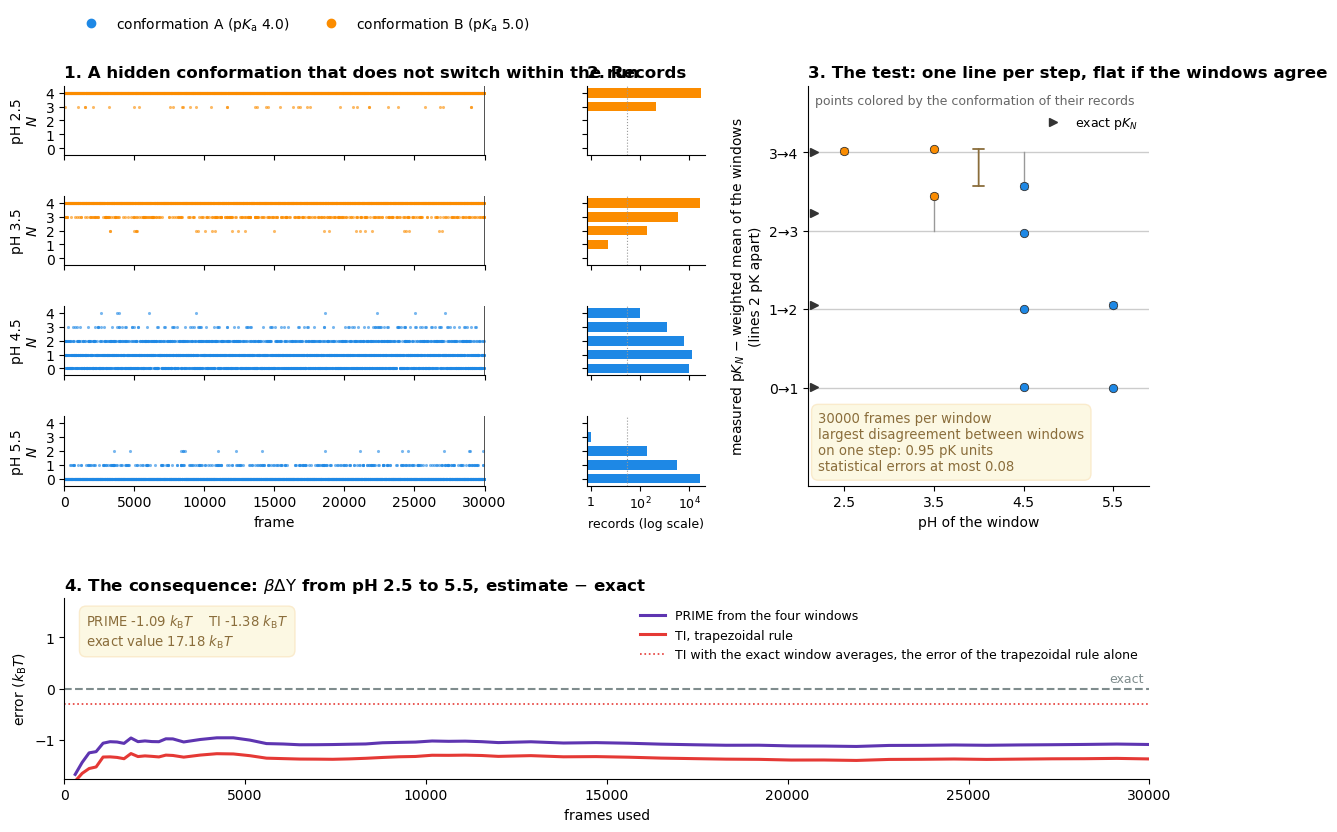

In [9]:
OFF = 2.0   # vertical spacing of the lines of the test panel, in pK units


def setup_test(ax):
    '''The test panel without its points. Returns the text box of the panel.'''
    for j in range(n_acid):
        ax.axhline(j * OFF, color='#cccccc', linewidth=1.0, zorder=0)
    ax.set_yticks(OFF * np.arange(n_acid))
    ax.set_yticklabels([f"{j}→{j + 1}" for j in range(n_acid)], fontsize=10)
    ax.set_ylim(-2.5, OFF * (n_acid - 1) + 1.7)
    ax.set_xlim(pHs_c[0] - 0.4, pHs_c[-1] + 0.4)
    ax.set_xticks(pHs_c)
    ax.set_xlabel("pH of the window", fontsize=10)
    ax.set_ylabel(f"measured p$K_N$ $-$ weighted mean of the windows\n(lines {OFF:g} pK apart)", fontsize=10)
    ax.text(0.02, 0.98, "points colored by the conformation of their records", transform=ax.transAxes, va='top',
            fontsize=9, color='#666666')
    ax.legend(handles=[plt.Line2D([], [], marker='>', ls='none', color='#333333', label=r'exact p$K_N$')],
              frameon=False, loc='upper right', bbox_to_anchor=(1.0, 0.955), fontsize=9)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    return ax.text(0.03, 0.03, '', transform=ax.transAxes, va='bottom', fontsize=9.5, color='#8a6d3b',
                   bbox=dict(facecolor='#fcf8e3', edgecolor='#faebcc', boxstyle='round,pad=0.5'))


def draw_test(ax, e, t, box):
    '''The points of the test panel for the estimates e after t frames. Returns the artists, to be removed before the next frame.'''
    art = []
    for j in range(n_acid):
        if not e["usable"][:, j].any():
            continue
        base = j * OFF
        for k in np.flatnonzero(e["usable"][:, j]):
            y = base + e["pK"][k, j] - e["pK_mean"][j]
            col = (1 - e["frac_B"][k, j]) * rgb_s[0] + e["frac_B"][k, j] * rgb_s[1]
            art += ax.plot([pHs_c[k], pHs_c[k]], [base, y], color='#999999', linewidth=1.0, zorder=1)
            art.append(ax.errorbar(pHs_c[k], y, yerr=e["se"][k, j], fmt='o', color=col, markeredgecolor='#333333',
                                   markeredgewidth=0.6, markersize=6, elinewidth=1.2, capsize=3, zorder=3))
        art += ax.plot(pHs_c[0] - 0.33, base + pK_eq[j] - e["pK_mean"][j], marker='>', color='#333333', markersize=6, ls='none')
    spread = {j: np.ptp(e["pK"][e["usable"][:, j], j]) for j in range(n_acid) if e["usable"][:, j].sum() >= 2}
    if spread:
        # a bracket spanning the two windows that disagree most, halfway between their pHs
        j = max(spread, key=spread.get)
        y = np.where(e["usable"][:, j], e["pK"][:, j] - e["pK_mean"][j] + j * OFF, np.nan)
        lo, hi = np.nanargmin(y), np.nanargmax(y)
        x = 0.5 * (pHs_c[lo] + pHs_c[hi])
        if np.min(np.abs(pHs_c - x)) < 0.2:   # not on top of a third window's point
            x += 0.25
        art.append(ax.annotate('', xy=(x, y[hi]), xytext=(x, y[lo]),
                               arrowprops=dict(arrowstyle='|-|, widthA=0.4, widthB=0.4', color='#8a6d3b', linewidth=1.3,
                                               shrinkA=0, shrinkB=0)))
        box.set_text(f"{t} frames per window\nlargest disagreement between windows\non one step: {spread[j]:.2f} pK units\n"
                     f"statistical errors at most {np.nanmax(e['se']):.2f}")
    else:
        box.set_text(f"{t} frames per window")
    return art


def setup_free(ax, span, legend=True):
    '''The free-energy panel without its curves, with the error axis from -span to span. Returns the two curves and the text box.'''
    ax.axhline(0, color='#7f8c8d', linewidth=1.5, linestyle='--')
    ax.text(0.995, 0.52, 'exact', transform=ax.transAxes, ha='right', va='bottom', fontsize=9, color='#7f8c8d')
    ax.axhline(dU_ti_eq - dU_eq, color='#e53935', linewidth=1.2, linestyle=':')
    line_prime, = ax.plot([], [], '-', color='#5e35b1', linewidth=2.2, label='PRIME from the four windows')
    line_ti, = ax.plot([], [], '-', color='#e53935', linewidth=2.2, label='TI, trapezoidal rule')
    ax.plot([], [], ':', color='#e53935', linewidth=1.2, label='TI with the exact window averages, the error of the trapezoidal rule alone')
    ax.set_xlim(0, T)
    ax.set_ylim(-span, span)
    ax.set_xlabel("frames used", fontsize=10)
    ax.set_ylabel(r"error ($k_\mathrm{B}T$)", fontsize=10)
    if legend:
        ax.legend(frameon=False, loc='upper right', fontsize=9)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    box = ax.text(0.02, 0.92, '', transform=ax.transAxes, va='top', fontsize=9.5, color='#8a6d3b',
                  bbox=dict(facecolor='#fcf8e3', edgecolor='#faebcc', boxstyle='round,pad=0.5'))
    return line_prime, line_ti, box


def draw_free(handles, dev, i):
    '''The curves of the free-energy panel up to the i-th time.'''
    line_prime, line_ti, box = handles
    line_prime.set_data(times[:i + 1], dev[:i + 1, 0])
    line_ti.set_data(times[:i + 1], dev[:i + 1, 1])
    box.set_text(f"PRIME {dev[i, 0]:+.2f} $k_\\mathrm{{B}}T$    TI {dev[i, 1]:+.2f} $k_\\mathrm{{B}}T$\nexact value {dU_eq:.2f} $k_\\mathrm{{B}}T$")


def consistency_movie(Nrec, srec, name, regime):
    '''The four panels over the frames used, as an animation and a final frame under Animations/name. Returns the running estimates.'''
    est = [running_estimates(Nrec, srec, t) for t in times]
    dev = np.array([[e["dU_prime"] - dU_eq, e["dU_ti"] - dU_eq] for e in est])
    fig = plt.figure(figsize=(14, 9))
    gs = fig.add_gridspec(K + 2, 3, width_ratios=[3.2, 0.9, 2.6], height_ratios=[1, 1, 1, 1, 0.45, 2.6], hspace=0.5, wspace=0.35)
    ax_traj = [fig.add_subplot(gs[k, 0]) for k in range(K)]
    ax_hist = [fig.add_subplot(gs[k, 1]) for k in range(K)]
    ax_test = fig.add_subplot(gs[:K, 2])
    ax_free = fig.add_subplot(gs[K + 1, :])
    tt = np.arange(0, T, 10)
    for k in range(K):
        ax = ax_traj[k]
        for sv in (0, 1):
            m = srec[k, tt] == sv
            ax.scatter(tt[m], Nrec[k, tt][m], s=5, color=colors_s[sv], alpha=0.6, linewidths=0, rasterized=True)
        ax.set_xlim(0, T)
        ax.set_ylim(-0.5, n_acid + 0.5)
        ax.set_yticks(n_arr)
        ax.set_ylabel(f"pH {pHs_c[k]}\n$N$", fontsize=10)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        if k < K - 1:
            ax.set_xticklabels([])
        ax = ax_hist[k]
        ax.set_xscale('log')
        ax.set_xlim(0.7, 1.5 * T)
        ax.set_xticks([1, 100, 10000])
        ax.set_xticklabels(['1', '$10^2$', '$10^4$'] if k == K - 1 else [], fontsize=9)
        ax.minorticks_off()
        ax.axvline(min_count, color='#999999', linewidth=0.8, linestyle=':')
        ax.set_yticks(n_arr)
        ax.set_yticklabels([])
        ax.set_ylim(-0.5, n_acid + 0.5)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
    ax_traj[0].set_title("1. " + regime, fontsize=12, weight='bold', loc='left')
    fig.legend(handles=[plt.Line2D([], [], marker='o', ls='none', color=colors_s[sv], label=names_s[sv]) for sv in (0, 1)],
               frameon=False, loc='lower left', bbox_to_anchor=(0.125, 0.925), fontsize=10, ncol=2, columnspacing=2.0)
    ax_traj[-1].set_xlabel("frame", fontsize=10)
    ax_hist[0].set_title("2. Records", fontsize=12, weight='bold', loc='left')
    ax_hist[-1].set_xlabel("records (log scale)", fontsize=9)
    cursors = [ax.axvline(0, color='#333333', linewidth=1.2, zorder=3) for ax in ax_traj]
    ax_test.set_title("3. The test: one line per step, flat if the windows agree", fontsize=12, weight='bold', loc='left')
    test_box = setup_test(ax_test)
    ax_free.set_title(r"4. The consequence: $\beta\Delta\Upsilon$ from pH 2.5 to 5.5, estimate $-$ exact", fontsize=12, weight='bold', loc='left')
    free_handles = setup_free(ax_free, 1.15 * np.nanmax(np.abs(dev[3:])))
    artists = []

    def update(i):
        for a in artists:
            a.remove()
        artists.clear()
        t, e = times[i], est[i]
        for k in range(K):
            cursors[k].set_xdata([t, t])
            artists.append(ax_traj[k].axvspan(t, T, color='white', alpha=0.65, linewidth=0, zorder=2))
            left = np.zeros(n_acid + 1)
            for sv in (0, 1):
                artists.append(ax_hist[k].barh(n_arr, e["H_by_s"][k, sv], left=left, color=colors_s[sv], height=0.7))
                left = left + e["H_by_s"][k, sv]
        artists.extend(draw_test(ax_test, e, t, test_box))
        draw_free(free_handles, dev, i)
        return cursors + artists + [test_box, *free_handles]

    frames = list(range(len(times))) + [len(times) - 1] * 28
    ani = animation.FuncAnimation(fig, update, frames=frames, interval=150, blit=False, repeat=True)
    ani.save(f'Animations/{name}.gif', writer='pillow', fps=7, dpi=100)
    if animation.writers.is_available('ffmpeg'):
        ani.save(f'Animations/{name}.mp4', writer='ffmpeg', fps=7, bitrate=1800, dpi=100)
    update(len(times) - 1)
    fig.savefig(f'Animations/{name}.png', dpi=200, bbox_inches='tight')
    return est, dev


def report(Nrec, est):
    '''The consistency test of prime on the full run, and the free energies of its last frame.'''
    H_full = prime.build_histograms(list(Nrec), pHs_c, n_sites=n_acid)
    h_blk = prime.block_histograms(list(Nrec), pHs_c, n_blocks=20, n_sites=n_acid)
    res = prime.consistency_test(H_full, pHs_c, h_blk, n_boot=200, min_count=min_count, max_se=0.5)
    print("tau per step (pK units):", np.round(res["tau"], 3))
    print(f"beta dUpsilon(2.5 -> 5.5): exact {dU_eq:.2f}, PRIME {est[-1]['dU_prime']:.2f}, TI {est[-1]['dU_ti']:.2f}, "
          f"TI with the exact window averages {dU_ti_eq:.2f}")


Nrec_slow, srec_slow = simulate_with_conformation(rate=1.0e-4)
print("conformation switches per window:", np.abs(np.diff(srec_slow, axis=1)).sum(axis=1))
est_slow, dev_slow = consistency_movie(Nrec_slow, srec_slow, 'PRIME_consistency_mechanism', "A hidden conformation that does not switch within the run")
report(Nrec_slow, est_slow)


**The control.** The same four windows with a conformation that switches throughout the run, as in the last animation of Section 4. Every window now visits both conformations in the proportions of its own pH, so the aggregated histogram converges and the residual is statistical scatter. The points of every step lie on their line, PRIME converges to the exact value, and TI converges to the exact value plus the error of its quadrature, the same $0.3\ k_\mathrm{B}T$ as in the slow run.


conformation switches per window: [2094 3923 5600  538]
tau per step (pK units): [0.    0.    0.034 0.   ]
beta dUpsilon(2.5 -> 5.5): exact 17.18, PRIME 17.13, TI 16.83, TI with the exact window averages 16.88


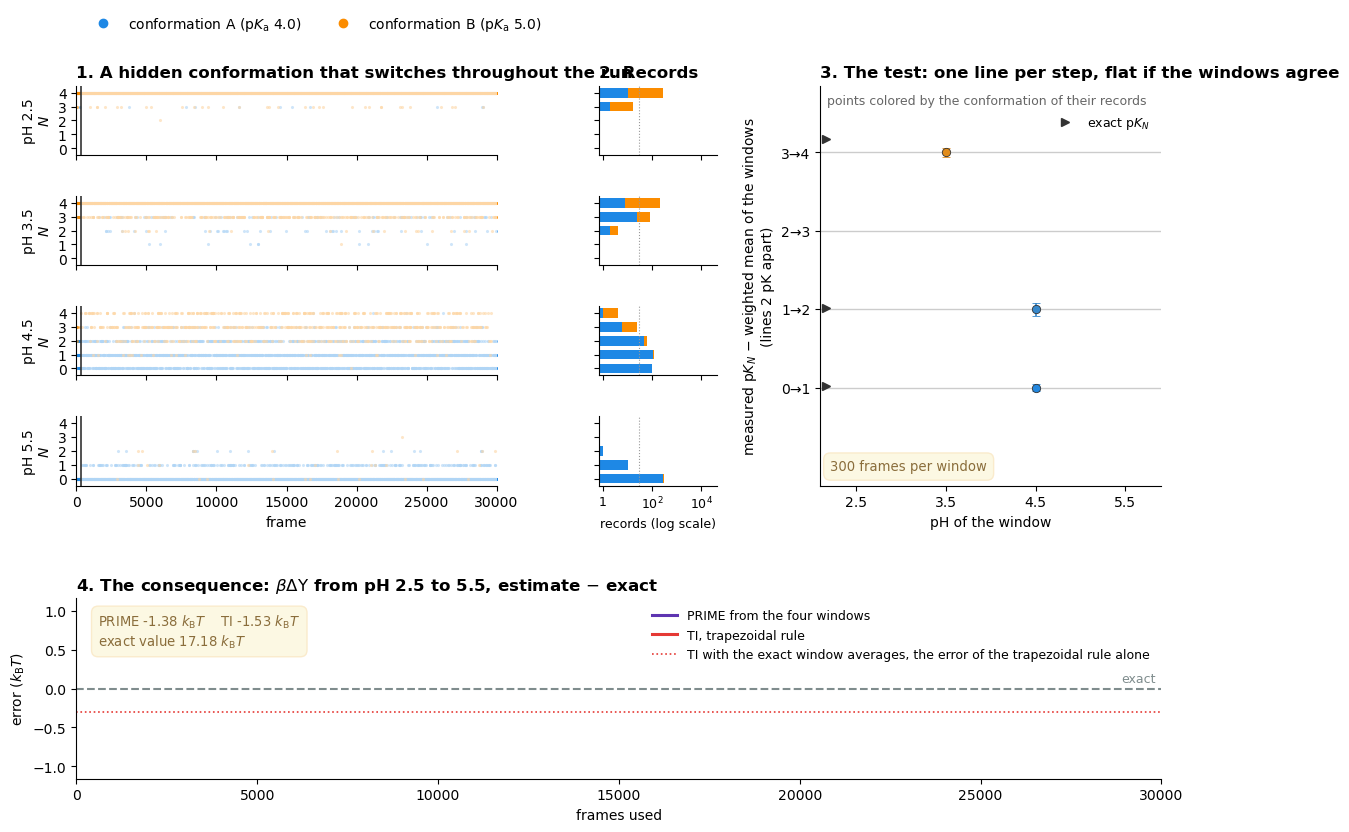

In [10]:
Nrec_fast, srec_fast = simulate_with_conformation(rate=1.0)
print("conformation switches per window:", np.abs(np.diff(srec_fast, axis=1)).sum(axis=1))
est_fast, dev_fast = consistency_movie(Nrec_fast, srec_fast, 'PRIME_consistency_control', "A hidden conformation that switches throughout the run")
report(Nrec_fast, est_fast)


**Side by side.** The final frames of the two runs, test and consequence only. Read together with Section 4, this is the argument of Section IV F of the manuscript and of Section S2 of the SI. Windows that keep different environments disagree on $\mathrm{p}K_N$, and the test shows the disagreement without any reference value. What the test shows is the residual, which the free energy of PRIME does not use. What makes the free energy wrong in the slow run is the part of the deviation that the windows share, which no estimator removes and no test can see. The two come from the same slow coordinate, which is why the manuscript reads the test as a check on the records rather than on the estimator. A clean test does not guarantee the free energy, since a deviation common to all windows passes it, and a failed test is a warning for every estimator alike, since the windows that disagree are the windows whose environments are wrong.


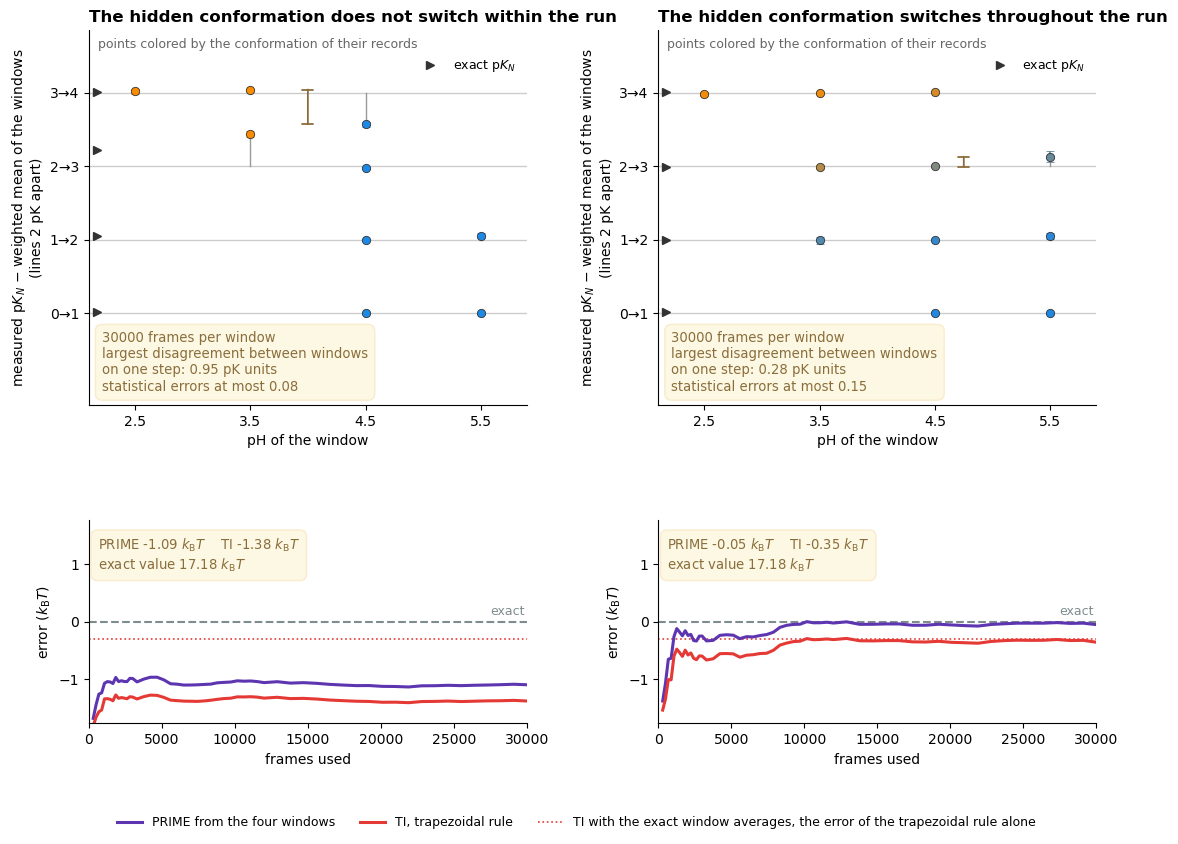

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), gridspec_kw=dict(height_ratios=[2.4, 1.3], hspace=0.4, wspace=0.3))
span = 1.15 * max(np.nanmax(np.abs(dev_slow[3:])), np.nanmax(np.abs(dev_fast[3:])))
for col, (regime, est, dev) in enumerate([("does not switch within the run", est_slow, dev_slow),
                                          ("switches throughout the run", est_fast, dev_fast)]):
    axes[0, col].set_title(f"The hidden conformation {regime}", fontsize=12, weight='bold', loc='left')
    draw_test(axes[0, col], est[-1], T, setup_test(axes[0, col]))
    draw_free(setup_free(axes[1, col], span, legend=False), dev, len(times) - 1)
fig.legend(*axes[1, 0].get_legend_handles_labels(), frameon=False, loc='lower center', bbox_to_anchor=(0.5, -0.02), ncol=3, fontsize=9)
fig.savefig('Animations/PRIME_consistency_slow_vs_fast.png', dpi=200, bbox_inches='tight')


**The split of Section S2 in numbers.** The deviation of a window from its converged histogram is $\varepsilon_k(N) = R_k(N) + M_k\,[P_k(N) - \Pr(N\mid k)]$, the residual plus the error of the estimate. The sampled mean of a window is then the mean of the histogram that PRIME assigns to it plus the first moment of the residual, and TI integrates both. The cell computes, from the full histograms of the two runs, the error of PRIME, the error of TI, and their difference split into the part the residual contributes, $\ln 10\,k_\mathrm{B}T$ times the trapezoidal integral of the first moments of the residual, and the quadrature error of the rule on the means that the estimate implies. The weighted sum of the residual moments is zero by the first sum rule of Section S2, which is why the residual that the test shows so clearly contributes almost nothing to TI over the full pH range of this grid. That is a property of this example and not of the method. The cancellation needs windows of equal length, the trapezoidal rule, and outer windows that are consistent, and it holds only for the integral over the whole range. The cell therefore also prints the two parts of TI minus PRIME at every window, and at the inner windows the residual part is as large as the quadrature part. On the fine grid of the manuscript the quadrature error is below $0.004\ k_\mathrm{B}T$ while the residual part is $0.06\ k_\mathrm{B}T$, so there the inconsistency is the main difference between the two estimators, the reverse of this example.


In [12]:
def split_of_the_error(Nrec, label):
    '''The error of PRIME and of TI on the full run, and the difference between them split as in Section S2 of the SI.'''
    rec = list(Nrec)
    H = prime.build_histograms(rec, pHs_c, n_sites=n_acid).astype(float)
    M = H.sum(axis=1)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", prime.PRIMEWarning)
        g = prime.solve_prime(H, pHs_c)
    lnc = prime.log_weights(g, H, pHs_c)
    # the histogram that the solution assigns to every window, M_k P_k(N), and the residual R_k(N) = H_k(N) - M_k P_k(N)
    assigned = M[:, None] * np.exp(lnc[None, :] + np.asarray(g)[:, None] - n_arr[None, :] * LN10 * pHs_c[:, None])
    residual = H - assigned
    # the sampled mean of a window is the mean of the assigned histogram plus the first moment of the residual
    mean_sampled = (n_arr * H).sum(axis=1) / M
    mean_assigned = (n_arr * assigned).sum(axis=1) / M
    moment = (n_arr * residual).sum(axis=1) / M
    var_sampled = (n_arr ** 2 * H).sum(axis=1) / M - mean_sampled ** 2
    var_assigned = (n_arr ** 2 * assigned).sum(axis=1) / M - mean_assigned ** 2
    ti_sampled_pH = prime.compute_TI_trapezoid(pHs_c, mean_sampled, var_sampled, M)[0]
    ti_assigned_pH = prime.compute_TI_trapezoid(pHs_c, mean_assigned, var_assigned, M)[0]
    ti_sampled, ti_assigned = ti_sampled_pH[-1], ti_assigned_pH[-1]
    print(f"{label}")
    print(f"  error of PRIME                      {g[-1] - dU_eq:+.3f} kT   the part of the deviation that the windows share")
    print(f"  error of TI                         {ti_sampled - dU_eq:+.3f} kT")
    print(f"  TI - PRIME                          {ti_sampled - g[-1]:+.3f} kT = residual {ti_sampled - ti_assigned:+.3f} + quadrature {ti_assigned - g[-1]:+.3f}")
    print(f"  first moment of the residual        {np.array2string(moment, precision=3, suppress_small=True)} per window, "
          f"weighted sum {np.dot(M, moment) / M.sum():+.3f}")
    print(f"  quadrature error with exact means   {dU_ti_eq - dU_eq:+.3f} kT")
    print(f"  TI - PRIME up to each window        residual {np.array2string(ti_sampled_pH - ti_assigned_pH, precision=3, suppress_small=True)}"
          f"   quadrature {np.array2string(ti_assigned_pH - np.asarray(g), precision=3, suppress_small=True)}")


split_of_the_error(Nrec_slow, "The conformation does not switch within the run")
split_of_the_error(Nrec_fast, "The conformation switches throughout the run")


The conformation does not switch within the run
  error of PRIME                      -1.094 kT   the part of the deviation that the windows share
  error of TI                         -1.376 kT
  TI - PRIME                          -0.282 kT = residual -0.002 + quadrature -0.280
  first moment of the residual        [-0.001  0.087 -0.089  0.003] per window, weighted sum +0.000
  quadrature error with exact means   -0.307 kT
  TI - PRIME up to each window        residual [ 0.     0.099  0.097 -0.002]   quadrature [ 0.    -0.108 -0.642 -0.28 ]
The conformation switches throughout the run
  error of PRIME                      -0.049 kT   the part of the deviation that the windows share
  error of TI                         -0.355 kT
  TI - PRIME                          -0.306 kT = residual -0.003 + quadrature -0.303
  first moment of the residual        [-0.002 -0.001 -0.002  0.004] per window, weighted sum +0.000
  quadrature error with exact means   -0.307 kT
  TI - PRIME up to each w